In [ ]:
!pip install tensorflow numpy matplotlib scikit-learn seaborn

# =======================================
#     CNN IMAGE CLASSIFICATION
#     Dataset: CIFAR-10
# =======================================

In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: []


In [4]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 392s 2us/step
Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000, 1)


In [5]:
# Match the variable names expected by the CNN code

X_train = x_train
X_test = x_test

print("Dataset variables connected successfully!")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Dataset variables connected successfully!
X_train: (50000, 32, 32, 3)
y_train: (50000, 1)
X_test: (10000, 32, 32, 3)
y_test: (10000, 1)


TensorFlow Version: 2.21.0

Dataset Shapes:
Training Images: (50000, 32, 32, 3)
Training Labels: (50000,)
Testing Images: (10000, 32, 32, 3)
Testing Labels: (10000,)

After Splitting:
Training: (42500, 32, 32, 3)
Validation: (7500, 32, 32, 3)
Testing: (10000, 32, 32, 3)


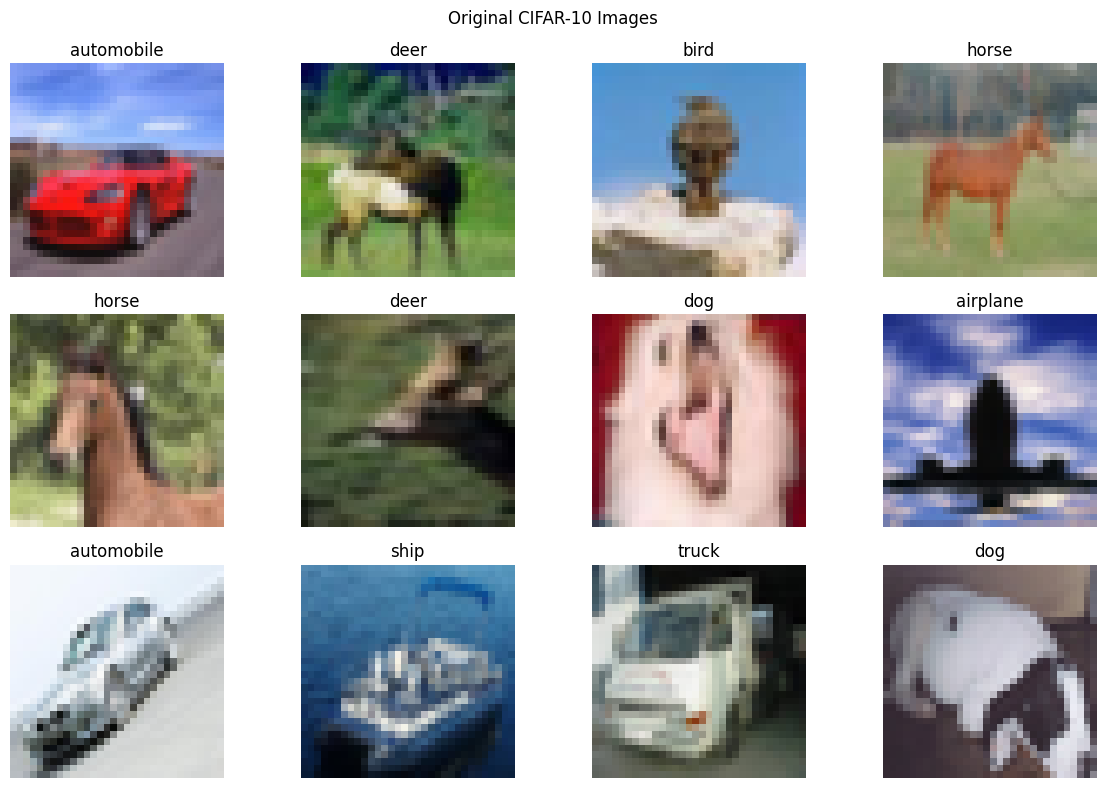

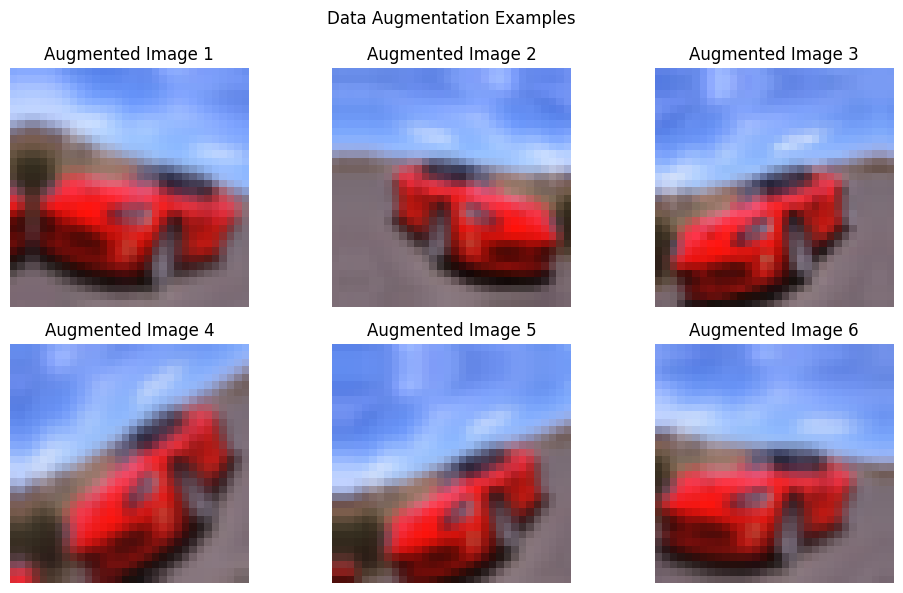

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 158,506 (619.16 KB)

 Trainable params: 157,866 (616.66 KB)

 Non-trainable params: 640 (2.50 KB)

Epoch 1/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 321s 475ms/step - accuracy: 0.3270 - loss: 1.8101 - val_accuracy: 0.2908 - val_loss: 2.0980 - learning_rate: 0.0010
Epoch 2/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 308s 463ms/step - accuracy: 0.4312 - loss: 1.5576 - val_accuracy: 0.4253 - val_loss: 1.6544 - learning_rate: 0.0010
Epoch 3/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 311s 467ms/step - accuracy: 0.4761 - loss: 1.4421 - val_accuracy: 0.4816 - val_loss: 1.4682 - learning_rate: 0.0010
Epoch 4/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 313s 453ms/step - accuracy: 0.5055 - loss: 1.3691 - val_accuracy: 0.3765 - val_loss: 1.8610 - learning_rate: 0.0010
Epoch 5/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 333s 470ms/step - accuracy: 0.5276 - loss: 1.3208 - val_accuracy: 0.5111 - val_loss: 1.3454 - learning_rate: 0.0010
Epoch 6/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 302s 454ms/step - accuracy: 0.5438 - loss: 1.2773 - val_accuracy: 0.4833 - val_loss: 1.5500 - learning_rate: 0.0010
Epoch 7/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 318s 448ms/step - accura

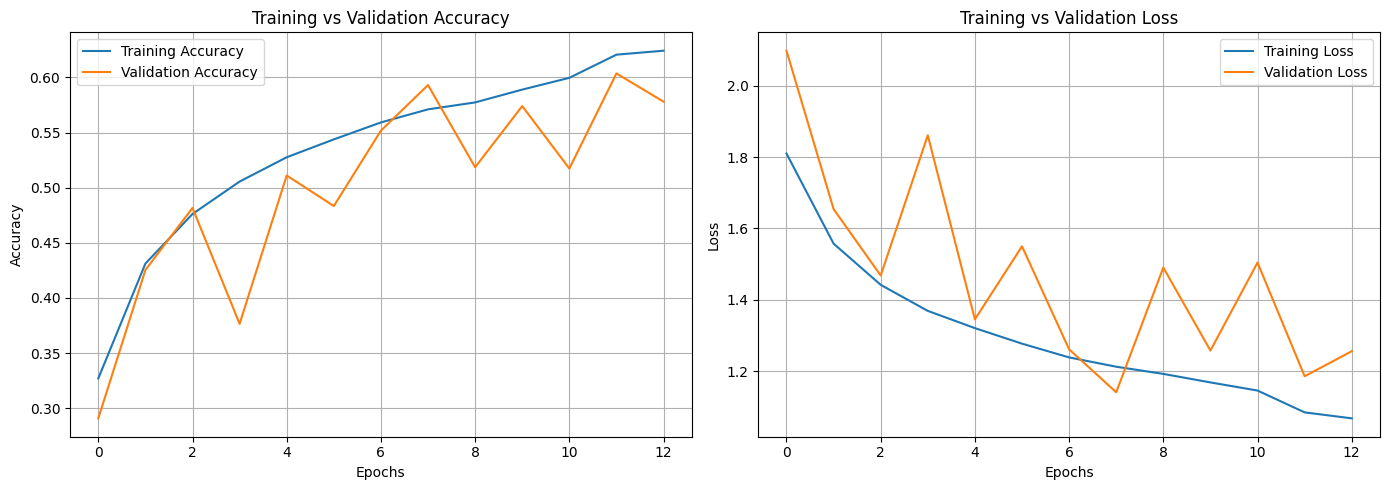

313/313 ━━━━━━━━━━━━━━━━━━━━ 16s 53ms/step - accuracy: 0.5957 - loss: 1.1430

========== MODEL PERFORMANCE ==========
Test Loss: 1.143
Test Accuracy: 59.57 %
157/157 ━━━━━━━━━━━━━━━━━━━━ 16s 103ms/step

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

    airplane       0.57      0.74      0.65      1000
  automobile       0.67      0.87      0.76      1000
        bird       0.69      0.23      0.34      1000
         cat       0.49      0.17      0.25      1000
        deer       0.54      0.47      0.51      1000
         dog       0.60      0.49      0.54      1000
        frog       0.53      0.73      0.62      1000
       horse       0.56      0.78      0.65      1000
        ship       0.73      0.69      0.71      1000
       truck       0.59      0.78      0.67      1000

    accuracy                           0.60     10000
   macro avg       0.60      0.60      0.57     10000
weighted avg       0.60      0.60      0.57     1

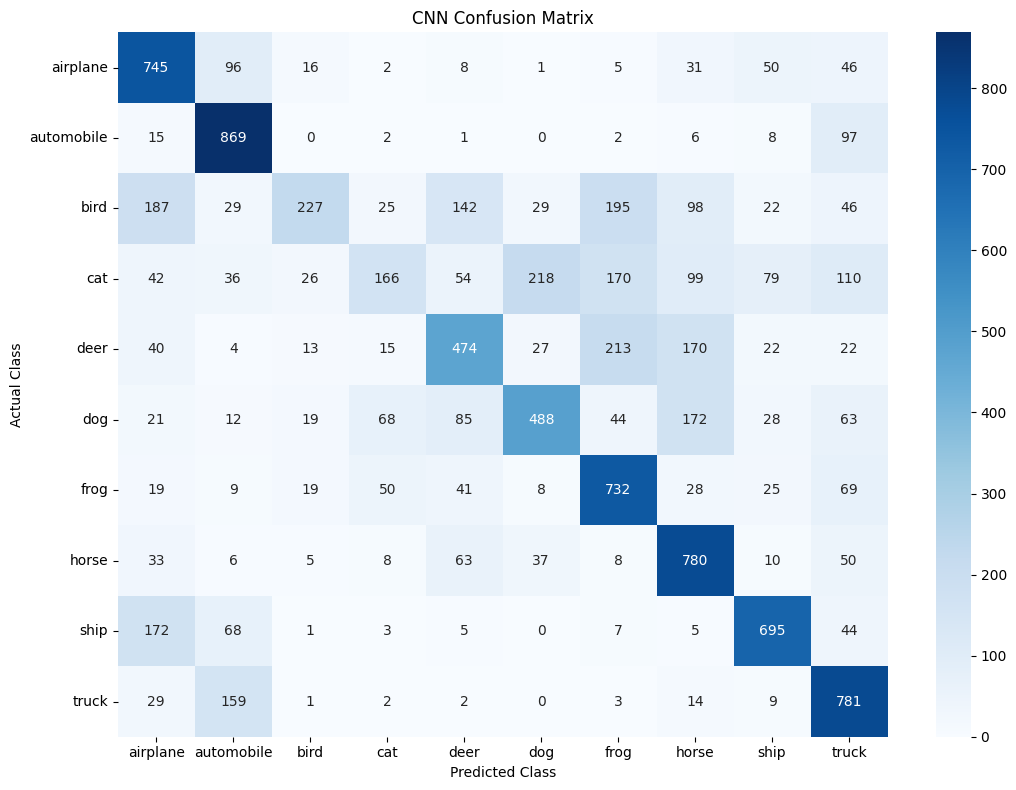

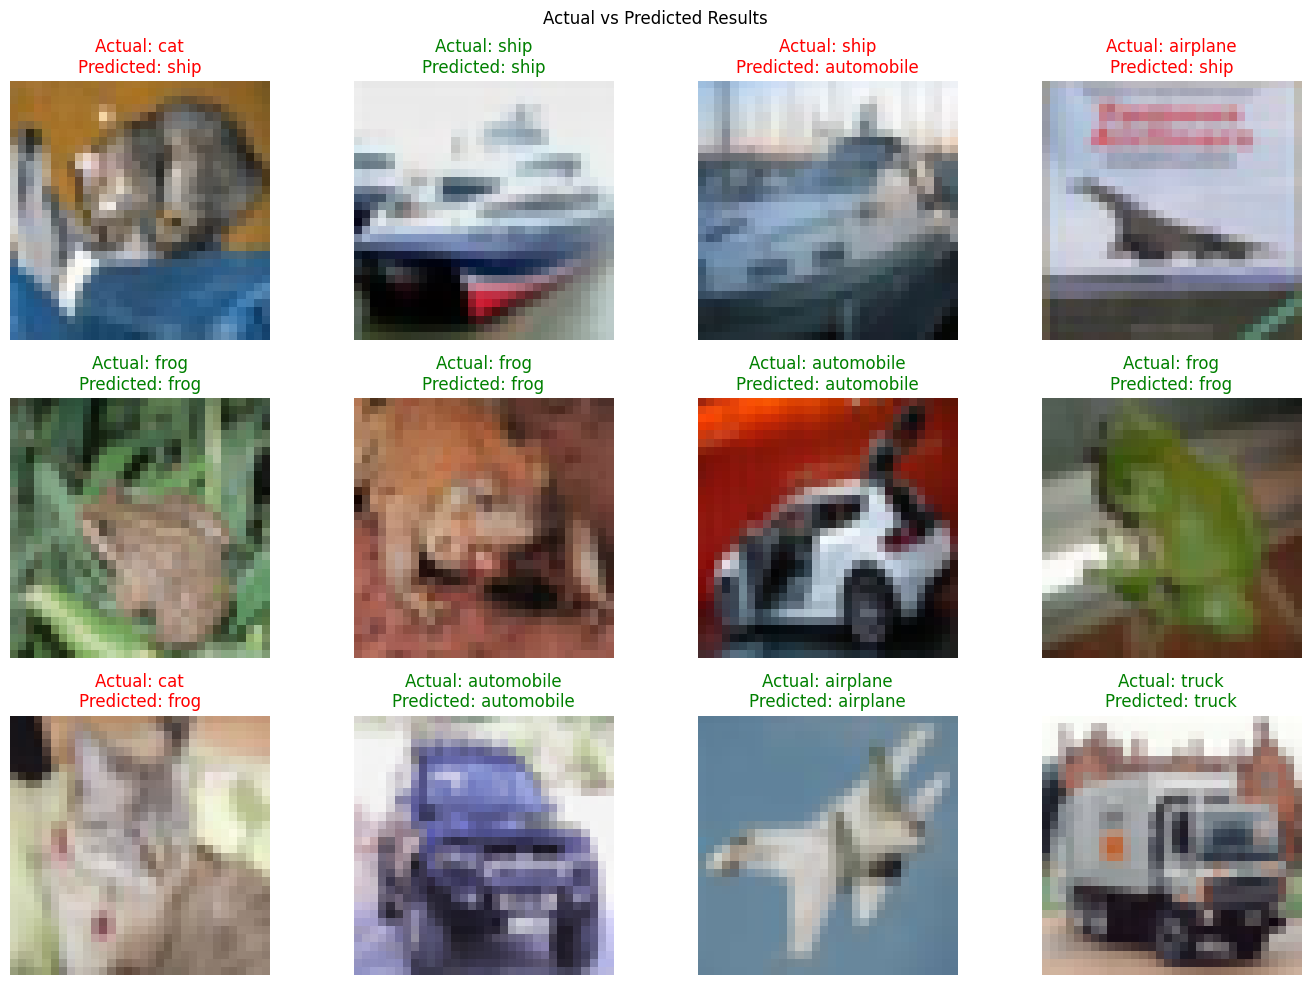

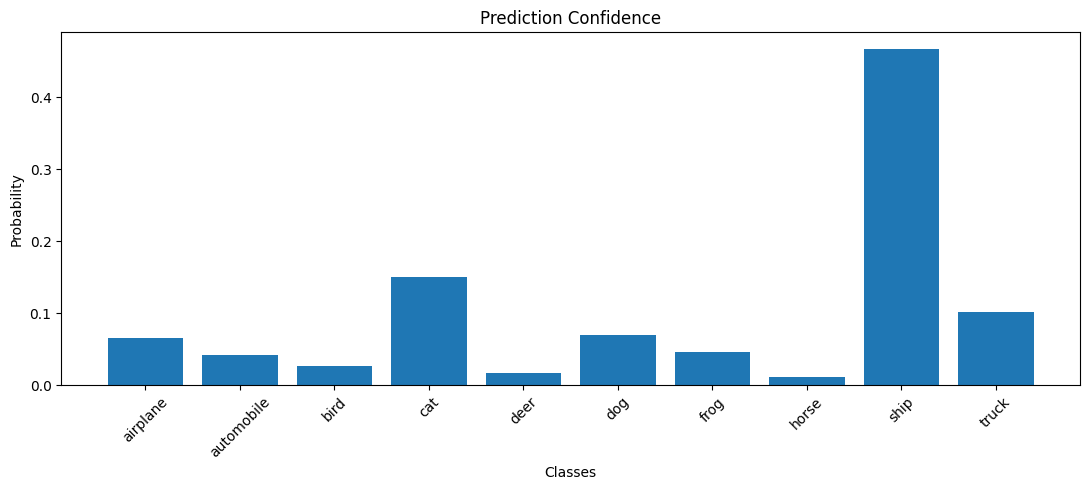


Predicted Class: ship
Actual Class: cat
Confidence: 46.64 %

Model saved successfully!
CNN Image Classification Project Completed!


In [6]:


import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow Version:", tf.__version__)


required_variables = ["x_train", "y_train", "x_test", "y_test"]

for variable in required_variables:
    if variable not in globals():
        raise NameError(
            f"{variable} is missing. Run your dataset-loading cell first."
        )

X_train = np.asarray(x_train).copy()
X_test = np.asarray(x_test).copy()
y_train = np.asarray(y_train).copy()
y_test = np.asarray(y_test).copy()


class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

num_classes = len(class_names)


# PREPROCESS IMAGES
# Check that images have the expected CIFAR-10 RGB shape.

if X_train.ndim != 4 or X_test.ndim != 4:
    raise ValueError(
        "Images must have 4 dimensions: "
        "(number_of_images, height, width, channels)."
    )

if X_train.shape[1:] != (32, 32, 3):
    raise ValueError(
        f"Expected training images of shape (32, 32, 3), "
        f"but received {X_train.shape[1:]}. "
        "This code is configured for CIFAR-10."
    )

if X_test.shape[1:] != (32, 32, 3):
    raise ValueError(
        f"Expected test images of shape (32, 32, 3), "
        f"but received {X_test.shape[1:]}."
    )

# Convert images to float32
X_train = X_train.astype("float32")
X_test = X_test.astype("float32")

# Normalize only if images are still in the 0-255 range
if X_train.max() > 1.0:
    X_train /= 255.0

if X_test.max() > 1.0:
    X_test /= 255.0


# PREPROCESS LABELS
def prepare_labels(labels):
    labels = np.asarray(labels)

    # Convert one-hot encoded labels to class indices
    if labels.ndim == 2 and labels.shape[1] > 1:
        labels = np.argmax(labels, axis=1)
    else:
        labels = labels.reshape(-1)

    return labels.astype("int64")


y_train = prepare_labels(y_train)
y_test = prepare_labels(y_test)

# Check label ranges
if np.any(y_train < 0) or np.any(y_train >= num_classes):
    raise ValueError("Training labels must be between 0 and 9.")

if np.any(y_test < 0) or np.any(y_test >= num_classes):
    raise ValueError("Testing labels must be between 0 and 9.")

if len(X_train) != len(y_train):
    raise ValueError("Training images and labels have different lengths.")

if len(X_test) != len(y_test):
    raise ValueError("Testing images and labels have different lengths.")

print("\nDataset Shapes:")
print("Training Images:", X_train.shape)
print("Training Labels:", y_train.shape)
print("Testing Images:", X_test.shape)
print("Testing Labels:", y_test.shape)


#  TRAIN-VALIDATION SPLIT
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train
)

print("\nAfter Splitting:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)



plt.figure(figsize=(12, 8))

for i in range(min(12, len(X_train))):
    plt.subplot(3, 4, i + 1)
    plt.imshow(np.clip(X_train[i], 0, 1))
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.suptitle("Original CIFAR-10 Images")
plt.tight_layout()
plt.show()


#  DATA AUGMENTATION
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.1)
], name="data_augmentation")


#  VISUALIZE AUGMENTED IMAGES
sample_image = tf.expand_dims(X_train[0], axis=0)

plt.figure(figsize=(10, 6))

for i in range(6):
    augmented_image = data_augmentation(
        sample_image,
        training=True
    )

    plt.subplot(2, 3, i + 1)
    plt.imshow(
        tf.clip_by_value(augmented_image[0], 0, 1)
    )
    plt.title(f"Augmented Image {i + 1}")
    plt.axis("off")

plt.suptitle("Data Augmentation Examples")
plt.tight_layout()
plt.show()


#  BUILD CNN MODEL
model = models.Sequential([

    layers.Input(shape=(32, 32, 3)),

    data_augmentation,

    # CNN BLOCK 1
    layers.Conv2D(32, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Conv2D(32, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # CNN BLOCK 2
    layers.Conv2D(64, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Conv2D(64, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.30),

    # CNN BLOCK 3
    layers.Conv2D(128, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.35),

    # CLASSIFICATION
    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(num_classes, activation="softmax")

])

model.summary()


#COMPILE MODEL
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


# CALLBACKS
callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.00001
    )

]


# 13. TRAIN MODEL
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=callbacks,
    verbose=1
)


# VISUALIZE ACCURACY AND LOSS
plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\n========== MODEL PERFORMANCE ==========")
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")


#  GENERATE PREDICTIONS
y_pred_prob = model.predict(X_test, batch_size=64)

y_pred = np.argmax(y_pred_prob, axis=1)



print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_test,
        y_pred,
        labels=list(range(num_classes)),
        target_names=class_names,
        zero_division=0
    )
)



cm = confusion_matrix(
    y_test,
    y_pred,
    labels=list(range(num_classes))
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


#  ACTUAL VS PREDICTED IMAGES
plt.figure(figsize=(14, 10))

for i in range(min(12, len(X_test))):

    plt.subplot(3, 4, i + 1)

    plt.imshow(np.clip(X_test[i], 0, 1))

    actual = class_names[int(y_test[i])]
    predicted = class_names[int(y_pred[i])]

    color = "green" if actual == predicted else "red"

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color=color
    )

    plt.axis("off")

plt.suptitle("Actual vs Predicted Results")
plt.tight_layout()
plt.show()


# PREDICTION CONFIDENCE
index = 0

probabilities = y_pred_prob[index]

plt.figure(figsize=(11, 5))

plt.bar(class_names, probabilities)

plt.title("Prediction Confidence")
plt.xlabel("Classes")
plt.ylabel("Probability")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

print("\nPredicted Class:", class_names[int(y_pred[index])])
print("Actual Class:", class_names[int(y_test[index])])

print(
    "Confidence:",
    round(float(np.max(probabilities)) * 100, 2),
    "%"
)


# SAVE MODEL
model.save("cnn_image_classifier.keras")

print("\nModel saved successfully!")
print("CNN Image Classification Project Completed!")
